# 02 — Новости о нефти: ознакомительный EDA

Первое знакомство с датасетом `data/processed/news/ru_oil_news.parquet`. Его
собирает пайплайн `src/news`: индекс Media Cloud (российские коллекции,
`language:ru`, нефтяные слова в заголовке) плюс полный текст статей с сайтов
изданий или из Wayback Machine.

Что смотрим:

1. загрузка и общая сводка;
2. распределение новостей во времени и пики;
3. источники: кто и сколько публикует, как меняется состав по годам;
4. длина текстов: перцентили, распределение, выбросы;
5. качество данных: live / wayback, перепечатки, даты;
6. дни недели;
7. темы в заголовках;
8. ложные срабатывания запроса;
9. что видно и что проверить дальше.

## 1. Загрузка

Ноутбук запускается из окружения проекта (`uv sync --all-groups`, kernel из
`.venv`). Корень проекта ищется автоматически — ближайшая папка с `src/`.

In [1]:
from pathlib import Path

import matplotlib.pyplot as plt
import matplotlib.ticker as mticker
import numpy as np
import pandas as pd


def find_project_root(start: Path | None = None) -> Path:
    """Ближайшая родительская папка, в которой есть src/."""

    current = (start or Path.cwd()).resolve()
    for candidate in [current, *current.parents]:
        if (candidate / "src").exists():
            return candidate
    msg = "Не найден корень проекта с папкой src/"
    raise FileNotFoundError(msg)


ROOT = find_project_root()
news = pd.read_parquet(ROOT / "data/processed/news/ru_oil_news.parquet")
news["length"] = news["text"].str.len()
news["words"] = news["text"].str.split().str.len()
# date - дата публикации после проверки по адресу и странице (см. раздел 5)
news["year"] = news["date"].dt.year
news["month"] = news["date"].dt.to_period("M")
news.shape

(117299, 25)

In [2]:
# Оформление: один акцентный цвет, приглушённые оси и сетка
BLUE = "#2a78d6"
ORANGE = "#eb6834"
INK = "#0b0b0b"
INK_SECONDARY = "#52514e"
GRID = "#e4e3df"

plt.rcParams.update(
    {
        "figure.figsize": (11, 4),
        "figure.dpi": 110,
        "axes.edgecolor": GRID,
        "axes.labelcolor": INK_SECONDARY,
        "axes.titlecolor": INK,
        "axes.titlesize": 13,
        "axes.titleweight": "bold",
        "axes.titlelocation": "left",
        "axes.spines.top": False,
        "axes.spines.right": False,
        "axes.grid": True,
        "axes.grid.axis": "y",
        "grid.color": GRID,
        "grid.linewidth": 0.8,
        "xtick.color": INK_SECONDARY,
        "ytick.color": INK_SECONDARY,
        "legend.frameon": False,
    },
)
thousands = mticker.FuncFormatter(lambda value, _: f"{value:,.0f}".replace(",", " "))

In [3]:
summary = pd.Series(
    {
        "статей": len(news),
        "период": f"{news['date'].min():%Y-%m-%d} – {news['date'].max():%Y-%m-%d}",
        "источников": news["media_name"].nunique(),
        "из Wayback": f"{(news['text_source'] == 'wayback').mean():.1%}",
        "перепечаток (duplicate_of)": news["duplicate_of"].notna().sum(),
        "медианная длина, символов": int(news["length"].median()),
    },
    name="значение",
)
summary.to_frame()

,значение
статей,117299
период,2015-02-19 – 2026-10-31
источников,91
из Wayback,1.9%
перепечаток (duplicate_of),343
"медианная длина, символов",1349


In [4]:
# Пропуски в ключевых колонках
key_columns = ["date", "media_name", "title", "url", "text", "extracted_date"]
news[key_columns].isna().mean().rename("доля пропусков").to_frame().style.format("{:.2%}")

,доля пропусков
date,0.00%
media_name,0.00%
title,0.00%
url,0.00%
text,0.00%
extracted_date,0.00%


## 2. Распределение новостей во времени

Число статей по месяцам. Подписаны три самых больших пика, ниже — заголовки из
них, чтобы понять, какие события их дали.

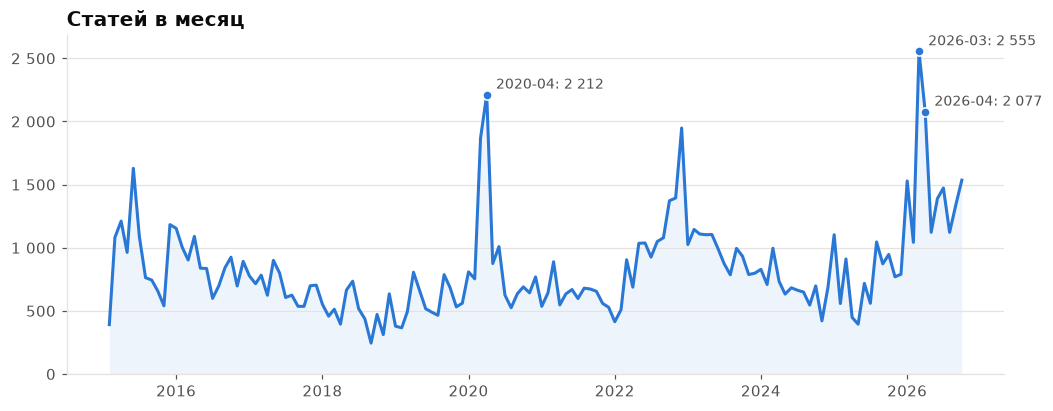

In [5]:
monthly = news.groupby("month").size()
monthly.index = monthly.index.to_timestamp()

fig, ax = plt.subplots()
ax.plot(monthly.index, monthly.values, color=BLUE, linewidth=2)
ax.fill_between(monthly.index, monthly.values, color=BLUE, alpha=0.08, linewidth=0)
for month, count in monthly.nlargest(3).items():
    ax.plot(month, count, "o", color=BLUE, markersize=6, markeredgecolor="white")
    ax.annotate(
        f"{month:%Y-%m}: {count:,}".replace(",", " "),
        (month, count),
        xytext=(6, 4),
        textcoords="offset points",
        color=INK_SECONDARY,
        fontsize=9,
    )
ax.set_title("Статей в месяц")
ax.set_ylim(0)
ax.yaxis.set_major_formatter(thousands)
plt.show()

In [6]:
yearly = news.groupby("year").size().rename("статей").to_frame()
yearly["в среднем за месяц"] = (
    news.groupby("year")["month"].nunique().rdiv(yearly["статей"]).round(0).astype(int)
)
yearly.T

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
статей,10254,10475,8304,5936,6743,11415,7612,12357,11654,8247,9118,15184
в среднем за месяц,932,873,692,495,562,951,634,1030,971,687,760,1518


In [7]:
# Что в пиках: по 5 заголовков из трёх самых насыщенных месяцев
for month in monthly.nlargest(3).index.to_period("M"):
    titles = news.loc[news["month"] == month, "title"].sample(5, random_state=0)
    print(f"== {month}")
    for title in titles:
        print("  -", title)

== 2026-03
  - Песков заявил о высоком спросе на российскую нефть
  - Цены на нефть ускорили рост на заявлениях Трампа об Иране
  - Дмитриев дал прогноз по нефтяному рынку: какие последствия будут от вывода войск США из Ормуза
  - Венгрия требует от ЕС приостановить вслед за США запрет на нефть из РФ — Сийярто
  - Цена за баррель нефти марки Brent приблизилась к отметке $120: что происходит на торговых площадках
== 2020-04
  - Рубль растет на новостях о договоренности России и Саудовской Аравии по нефти
  - Нефтедобыча ОПЕК+ не хочет угасать без жгучей Мексики. Обзор
  - Нефть некуда больше складывать
  - Участие США в переговорах ОПЕК+ назвали ключевым: Госэкономика: Экономика: Lenta.ru
  - «Все, приплыли»: Эксперт объяснил, что значит отрицательная цена на нефть для России
== 2026-04
  - В России призвали к жесткому ответу на атаку на НПЗ в Туапсе
  - Российскому бюджету спрогнозировали резкий рост нефтегазовых доходов
  - Бессент: более десяти стран просят США не ужесточать санкции 

## 3. Источники

Сколько публикаций у каждого издания и насколько корпус сосредоточен в
нескольких крупных источниках.

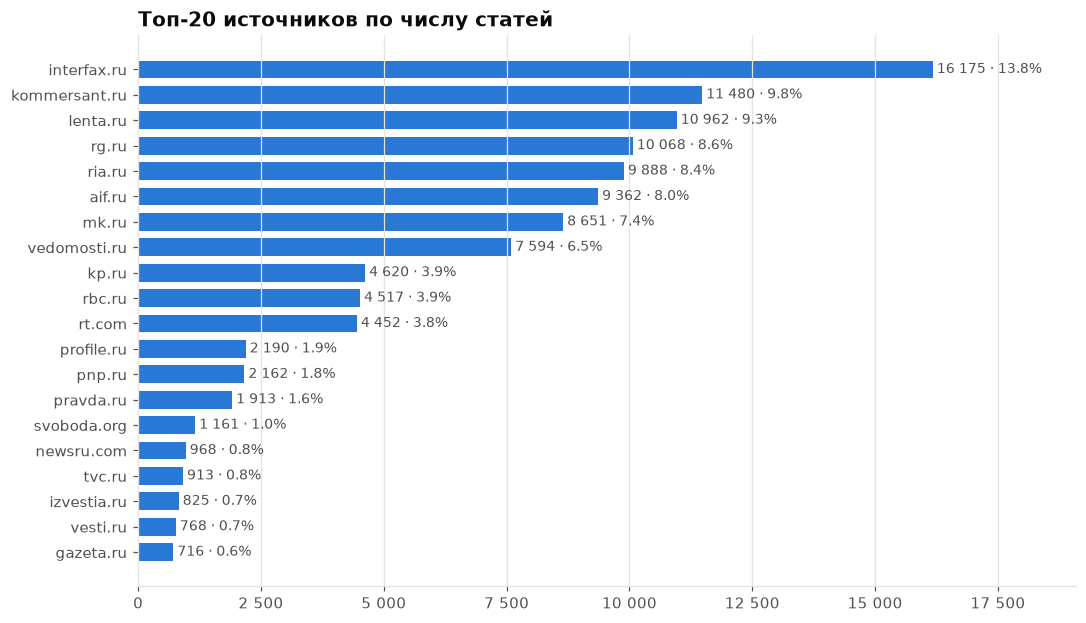

In [8]:
by_source = news["media_name"].value_counts()
top = by_source.head(20).iloc[::-1]

fig, ax = plt.subplots(figsize=(11, 6.5))
ax.barh(top.index, top.values, color=BLUE, height=0.7)
for position, (source, count) in enumerate(top.items()):
    ax.text(
        count,
        position,
        f" {count:,} · {count / len(news):.1%}".replace(",", " "),
        va="center",
        color=INK_SECONDARY,
        fontsize=9,
    )
ax.set_title("Топ-20 источников по числу статей")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(thousands)
ax.set_xlim(0, top.max() * 1.18)
plt.show()

In [9]:
share = by_source.cumsum() / by_source.sum()
pd.Series(
    {
        "источников всего": len(by_source),
        "дают 50% статей": int((share < 0.5).sum() + 1),
        "дают 80% статей": int((share < 0.8).sum() + 1),
        "источников < 100 статей": int((by_source < 100).sum()),
    },
    name="значение",
).to_frame()

,значение
источников всего,91
дают 50% статей,6
дают 80% статей,11
источников < 100 статей,46


**Состав источников по годам.** Media Cloud собирает каждый источник с момента,
когда начал читать его RSS, поэтому состав корпуса со временем может меняться.
Тепловая карта: доля статей года, которую дал источник.

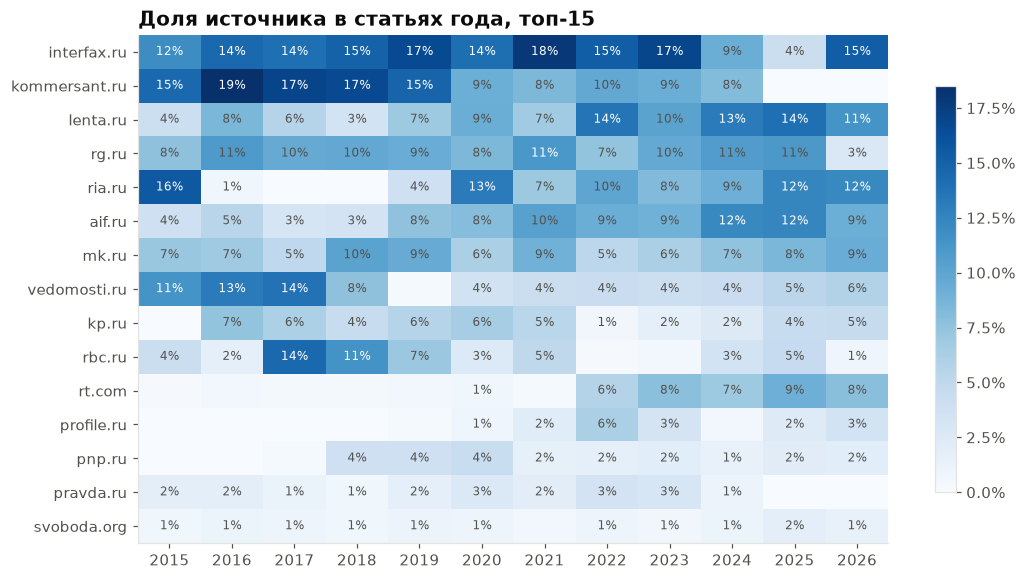

In [10]:
top_sources = by_source.head(15).index
mix = pd.crosstab(news["media_name"], news["year"], normalize="columns").loc[top_sources]

fig, ax = plt.subplots(figsize=(11, 6))
image = ax.imshow(mix.values, aspect="auto", cmap="Blues", vmin=0)
ax.set_xticks(range(len(mix.columns)), mix.columns)
ax.set_yticks(range(len(mix.index)), mix.index)
ax.grid(visible=False)
for (row, column), value in np.ndenumerate(mix.values):
    if value >= 0.005:
        ax.text(
            column,
            row,
            f"{value:.0%}",
            ha="center",
            va="center",
            fontsize=8,
            color="white" if value > mix.values.max() * 0.6 else INK_SECONDARY,
        )
ax.set_title("Доля источника в статьях года, топ-15")
fig.colorbar(image, ax=ax, format=mticker.PercentFormatter(1.0), shrink=0.8)
plt.show()

## 4. Длина текстов

Длина в символах и словах: перцентили, распределение и выбросы. Тексты короче
300 символов пайплайн не берёт (`MIN_TEXT_CHARS`), поэтому слева распределение
обрезано.

In [11]:
percentiles = [0.05, 0.25, 0.5, 0.75, 0.95, 0.99]
news[["length", "words"]].describe(percentiles=percentiles).rename(
    columns={"length": "символов", "words": "слов"},
).round(0)

,символов,слов
count,117299.0,117299.0
mean,1875.0,259.0
std,1908.0,265.0
min,300.0,19.0
5%,509.0,70.0
25%,884.0,122.0
50%,1349.0,186.0
75%,2180.0,298.0
95%,4946.0,688.0
99%,9431.0,1299.0


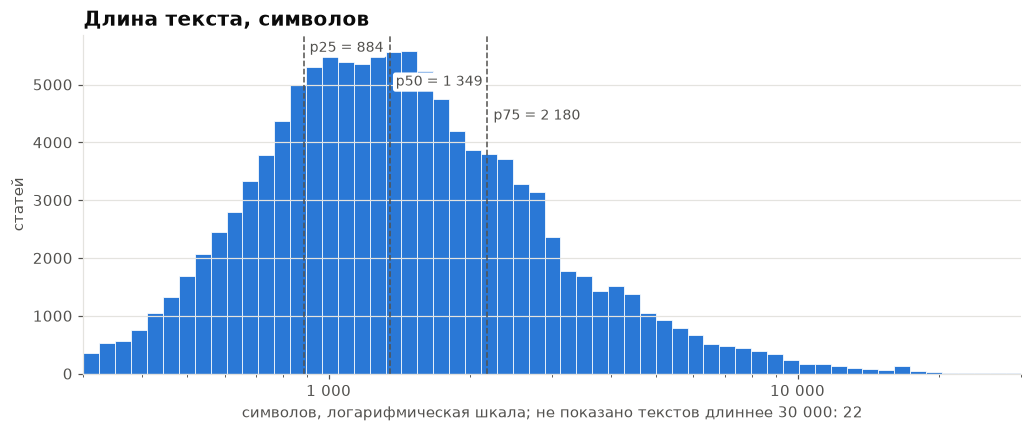

In [12]:
fig, ax = plt.subplots()
bins = np.logspace(np.log10(300), np.log10(news["length"].max()), 80)
ax.hist(news["length"], bins=bins, color=BLUE, edgecolor="white", linewidth=0.5)
ax.set_xscale("log")
ax.xaxis.set_major_formatter(thousands)
# Подписи ступенькой, чтобы три близкие линии не наезжали друг на друга
for quantile, height in ((0.25, 0.95), (0.5, 0.85), (0.75, 0.75)):
    value = news["length"].quantile(quantile)
    ax.axvline(value, color=INK_SECONDARY, linewidth=1, linestyle="--")
    ax.annotate(
        f"p{int(quantile * 100)} = {value:,.0f}".replace(",", " "),
        (value, ax.get_ylim()[1] * height),
        xytext=(4, 0),
        textcoords="offset points",
        color=INK_SECONDARY,
        fontsize=9,
        bbox={"boxstyle": "round,pad=0.2", "facecolor": "white", "edgecolor": "none"},
    )
ax.set_xlim(300, 30_000)
outside = (news["length"] > 30_000).sum()
ax.set_title("Длина текста, символов")
ax.set_xlabel(f"символов, логарифмическая шкала; не показано текстов длиннее 30 000: {outside}")
ax.set_ylabel("статей")
plt.show()

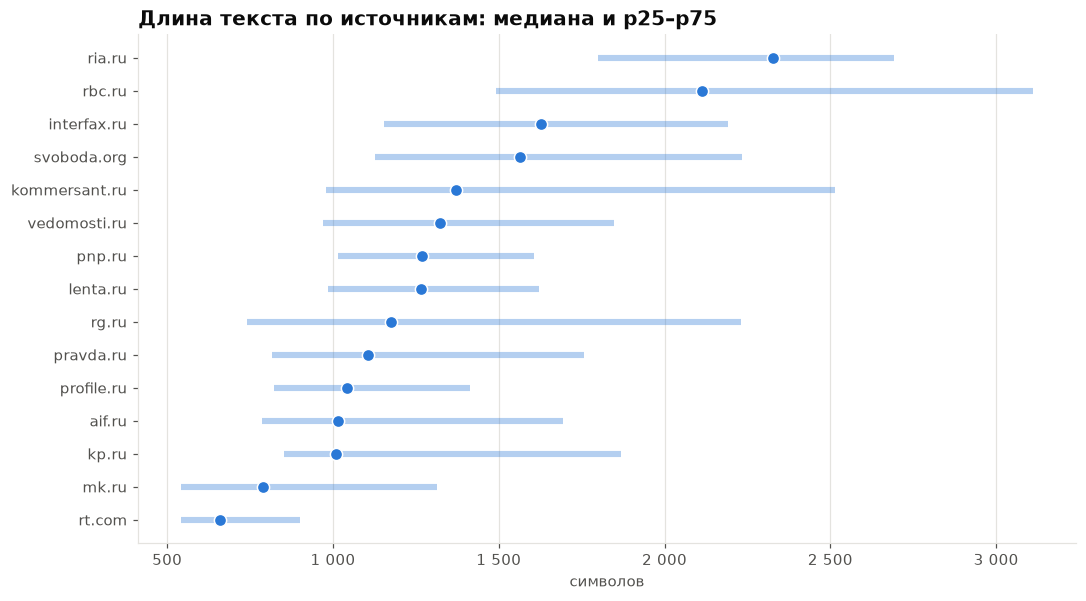

In [13]:
# Длина по источникам: медиана и межквартильный размах, топ-15
lengths = (
    news[news["media_name"].isin(top_sources)]
    .groupby("media_name")["length"]
    .quantile([0.25, 0.5, 0.75])
    .unstack()
    .sort_values(0.5)
)

fig, ax = plt.subplots(figsize=(11, 6))
ax.hlines(lengths.index, lengths[0.25], lengths[0.75], color=BLUE, linewidth=4, alpha=0.35)
ax.plot(lengths[0.5], lengths.index, "o", color=BLUE, markersize=8, markeredgecolor="white")
ax.set_title("Длина текста по источникам: медиана и p25–p75")
ax.set_xlabel("символов")
ax.grid(axis="y", visible=False)
ax.grid(axis="x", visible=True)
ax.xaxis.set_major_formatter(thousands)
plt.show()

In [14]:
# Самые длинные тексты: статья или страница с лентой/комментариями?
longest = news.nlargest(5, "length")[["date", "media_name", "length", "title", "url"]]
longest

,date,media_name,length,title,url
51414,2020-10-19,rg.ru,143126,Федеральный закон от 15 октября 2020 г. N 321-...,https://rg.ru/2020/10/19/nalogi-dok.html
21597,2017-02-03,rg.ru,66641,Постановление Конституционного Суда Российской...,https://rg.ru/2017/02/03/konstsudyukosdok-dok....
56205,2021-05-25,svoboda.org,48524,Концы в тундру. Афера нефтяников по закапывани...,https://www.svoboda.org/a/31225529.html
7667,2015-09-21,svoboda.org,46978,Второй пошел: нефть и Гайзер. Эфир в 19:05,http://www.svoboda.org/content/transcript/2725...
59652,2021-11-01,svoboda.org,44124,Шантаж Европы и закат нефтяной России?,https://www.svoboda.org/a/31539301.html


## 5. Качество данных

- **live / wayback** по годам: откуда взят текст;
- **перепечатки**: одинаковый текст в разных изданиях (`duplicate_of`);
- **даты**: совпадает ли дата публикации из Media Cloud с датой, которую
  trafilatura нашла на странице.

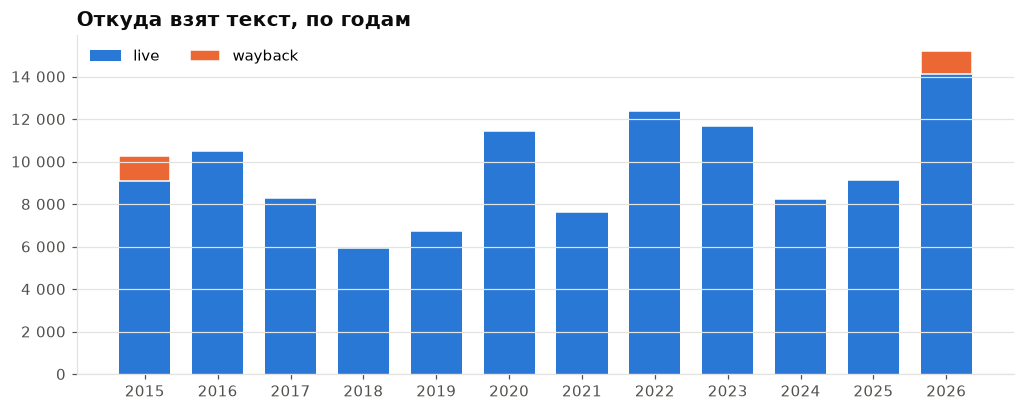

year,2015,2016,2017,2018,2019,2020,2021,2022,2023,2024,2025,2026
доля wayback,11.3%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,0.0%,6.9%


In [15]:
sources_by_year = pd.crosstab(news["year"], news["text_source"])[["live", "wayback"]]

fig, ax = plt.subplots()
ax.bar(sources_by_year.index, sources_by_year["live"], color=BLUE, label="live", width=0.7)
ax.bar(
    sources_by_year.index,
    sources_by_year["wayback"],
    bottom=sources_by_year["live"],
    color=ORANGE,
    label="wayback",
    width=0.7,
    edgecolor="white",
    linewidth=1,
)
ax.set_title("Откуда взят текст, по годам")
ax.set_xticks(sources_by_year.index)
ax.yaxis.set_major_formatter(thousands)
ax.legend(loc="upper left", ncols=2)
plt.show()

(sources_by_year["wayback"] / sources_by_year.sum(axis=1)).rename("доля wayback").to_frame().T.style.format("{:.1%}")

In [16]:
# Перепечатка внутри одного сайта - это одна статья по двум адресам
reprints = news[news["duplicate_of"].notna()]
originals = news.set_index("story_id").loc[reprints["duplicate_of"], "media_name"]
same_site = reprints["media_name"].to_numpy() == originals.to_numpy()
print(f"перепечаток: {len(reprints)}, из них внутри одного сайта: {same_site.mean():.1%}")
reprints["media_name"].value_counts().head(10).rename("перепечаток").to_frame()

перепечаток: 343, из них внутри одного сайта: 98.8%


,перепечаток
media_name,
kp.ru,205
rg.ru,26
interfax.ru,15
aif.ru,14
mk.ru,13
vedomosti.ru,13
sports.ru,11
ria.ru,8
rt.com,7


**Даты.** Media Cloud иногда ставит дату импорта вместо даты публикации: сотни
статей источника на один день. Поэтому `assemble` выбирает дату так: из адреса
статьи (`/2017/05/12/`), если её там нет и дата Media Cloud попала в такой
кластер — со страницы, иначе — дату Media Cloud. Откуда взята дата, видно в
`date_source`; `unreliable` — кластер, для которого другой даты не нашлось.

In [17]:
display(news["date_source"].value_counts().rename("статей").to_frame())
moved = (news["date"] - news["publish_date"]).dt.days.abs() > 7
print(f"дата сдвинута больше чем на неделю: {moved.sum()} статей")
news.loc[news["date_source"] == "unreliable", "media_name"].value_counts().head(5).rename(
    "unreliable по источникам",
).to_frame()

,статей
date_source,
media_cloud,62065
url,53698
page,805
unreliable,731


дата сдвинута больше чем на неделю: 1956 статей


,unreliable по источникам
media_name,
profile.ru,731


In [18]:
# Как исправление дат поменяло помесячную картину
by_publish = news.groupby(news["publish_date"].dt.to_period("M")).size()
by_date = news.groupby("month").size()
changed = pd.DataFrame({"дата Media Cloud": by_publish, "исправленная дата": by_date}).fillna(0).astype(int)
changed[(changed.iloc[:, 0] - changed.iloc[:, 1]).abs() > 100]

,дата Media Cloud,исправленная дата
2016-12,2746,892
2017-03,681,783
2017-05,756,900
2017-06,670,799
2017-11,593,699
2017-12,585,704


## 6. Дни недели

Отчёт EIA Weekly Petroleum Status Report выходит по средам, поэтому интересно,
как поток новостей распределён по дням недели.

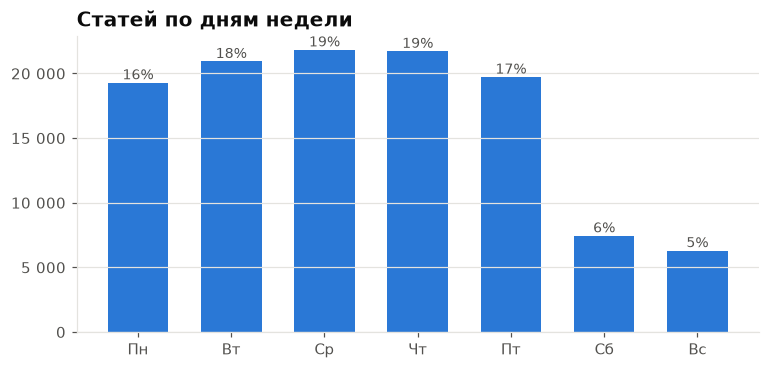

In [19]:
weekdays = ["Пн", "Вт", "Ср", "Чт", "Пт", "Сб", "Вс"]
by_weekday = news["date"].dt.day_of_week.value_counts().sort_index()

fig, ax = plt.subplots(figsize=(8, 3.5))
ax.bar(weekdays, by_weekday.values, color=BLUE, width=0.65)
for position, count in enumerate(by_weekday.values):
    ax.text(position, count, f"{count / len(news):.0%}", ha="center", va="bottom", color=INK_SECONDARY, fontsize=9)
ax.set_title("Статей по дням недели")
ax.yaxis.set_major_formatter(thousands)
plt.show()

## 7. Темы в заголовках

Грубая разметка заголовков по словарю тем: доля статей месяца, в заголовке
которых встречается тема. Одна статья может попасть в несколько тем. Все панели
на одной шкале.

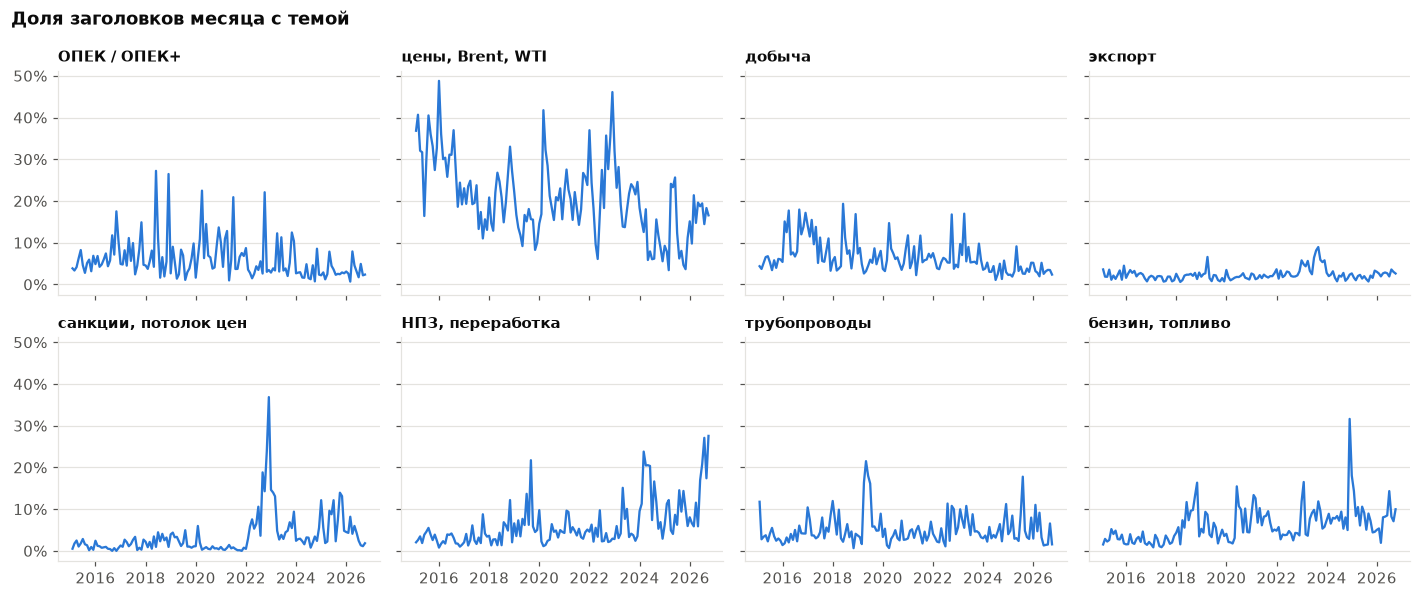

,доля статей
"цены, Brent, WTI",21.4%
"НПЗ, переработка",6.5%
добыча,6.5%
ОПЕК / ОПЕК+,6.0%
"бензин, топливо",6.0%
трубопроводы,5.0%
"санкции, потолок цен",4.4%
экспорт,2.4%


In [20]:
themes = {
    "ОПЕК / ОПЕК+": r"\bопек\b|опек\+|\bopec",
    "цены, Brent, WTI": r"\bцен[аыуе]?\b|brent|wti|подорожа|подешев|баррел",
    "добыча": r"добыч",
    "экспорт": r"экспорт",
    "санкции, потолок цен": r"санкц|потол[оки]",
    "НПЗ, переработка": r"нпз|переработ|нефтеперераб",
    "трубопроводы": r"нефтепровод|трубопровод|транснефт|дружб",
    "бензин, топливо": r"бензин|топлив|дизел|нефтепродукт",
}
titles = news["title"].str.lower()
theme_flags = pd.DataFrame({name: titles.str.contains(pattern, regex=True) for name, pattern in themes.items()})
theme_share = theme_flags.groupby(news["month"]).mean()
theme_share.index = theme_share.index.to_timestamp()

fig, axes = plt.subplots(2, 4, figsize=(13, 5.5), sharex=True, sharey=True)
for ax, name in zip(axes.flat, themes, strict=True):
    ax.plot(theme_share.index, theme_share[name], color=BLUE, linewidth=1.5)
    ax.set_title(name, fontsize=10)
    ax.yaxis.set_major_formatter(mticker.PercentFormatter(1.0, decimals=0))
fig.suptitle("Доля заголовков месяца с темой", x=0.01, ha="left", fontweight="bold", color=INK)
fig.tight_layout()
plt.show()

theme_flags.mean().sort_values(ascending=False).rename("доля статей").to_frame().style.format("{:.1%}")

## 8. Ложные срабатывания запроса

Запрос ловил не только нефть: `нефт*` находил хоккейный клуб «Нефтехимик» и
футбольный «Нефтчи», а `ОПЕК*` — «опекуна» и «опеку». Теперь запрос исключает
эти слова, а `assemble` дополнительно отбрасывает такие заголовки
(`title_exclude` в настройках). Проверим, сколько шума было в индексе и что в
датасете его не осталось.

In [21]:
noise = {
    "клубы «Нефтехимик», «Нефтчи»": r"нефтехимик|нефтчи",
    "опека, опекун": r"опек(?!\b|\+)",
}
index_titles = pd.read_parquet(ROOT / "data/interim/news/stories.parquet", columns=["title"])["title"].str.lower()
pd.DataFrame(
    {
        "в индексе Media Cloud": {name: index_titles.str.contains(pattern, regex=True).sum() for name, pattern in noise.items()},
        "в датасете": {name: titles.str.contains(pattern, regex=True).sum() for name, pattern in noise.items()},
    },
)

,в индексе Media Cloud,в датасете
"клубы «Нефтехимик», «Нефтчи»",6593,0
"опека, опекун",4481,0


In [22]:
# Остальной спорт: заголовки, где нефть упоминается мимоходом
sport = titles.str.contains(r"\bматч|кхл|\bгол\b|хоккей|футбол", regex=True)
print(f"спортивных заголовков: {sport.mean():.2%}")
for title in news.loc[sport, "title"].sample(5, random_state=1):
    print("  -", title)

спортивных заголовков: 0.50%
  - «Роснефть» отказалась финансировать футбольный клуб «Томь»
  - Чернышов про Fan ID: «У нас многие законы принимают, не спрашивая людей. Принимающие решения далеки от футбола. А это другая сфера, это не нефтяной бизнес, например»
  - Омский НПЗ поддержал первенство студенческой хоккейной лиги
  - «Транснефть» вновь выставила на продажу долю в КХЛ
  - Чемпионат России по волейболу. 8-й тур. «Нефтяник» на тай-брейке уступил «Енисею», «Югра-Самотлор» обыграла «Урал» и другие матчи


## 9. Что видно и что проверить дальше

**Что видно на этом срезе:**

- Корпус сосредоточен в крупных федеральных изданиях: 6 источников дают
  половину статей, 11 — 80%.
- Состав источников сильно меняется по годам: ria.ru почти нет в 2016–2018,
  kommersant.ru пропадает в 2025–2026, rt.com появляется с 2022-го. Объём новостей
  по времени отражает не только события, но и покрытие Media Cloud.
- Пики — 2020-04 (обвал цен и сделка ОПЕК+), 2026-03/04 (Иран, Ормузский пролив),
  2022-12 (потолок цен). Пик 2016-12 был артефактом дат Media Cloud (rbc.ru,
  2016-12-22) и после исправления дат пропал.
- Даты: больше половины статей проверены по адресу; у 731 статьи profile.ru
  дата ненадёжна (`date_source = unreliable`).
- Медианная статья — около 1,35 тыс. символов (p25–p75: 0,9–2,2 тыс.). Самые
  длинные тексты — законы на rg.ru и расшифровки эфиров svoboda.org, не новости.
- В выходные новостей в 2–3 раза меньше, чем в будни.
- Шум запроса («Нефтехимик», «Нефтчи», «опека») отфильтрован; остаточный спорт —
  около 0,5% заголовков, и часть из них действительно про нефтяные компании.

**Что проверить дальше:**

- Состав источников: нормировать объём новостей на покрытие источника, чтобы
  модель не училась на изменениях Media Cloud.
- Статьи с `date_source = unreliable`: выбросить или датировать по соседним
  статьям источника.
- Длинные тексты: отрезать или выбросить законы, расшифровки и ленты.
- Перепечатки почти все внутри одного сайта, то есть это одна статья по двум
  адресам; для признаков их стоит выбросить.